In [2]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              RandomForestClassifier, GradientBoostingClassifier)
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, classification_report,
                             silhouette_score, davies_bouldin_score, adjusted_rand_score)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
sns.set_style("whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

DATA_CANDIDATES = ["/content/Marks-3.xlsx"]
DATA_PATH = next((p for p in DATA_CANDIDATES if os.path.exists(p)), DATA_CANDIDATES[0])
SHEET_NAME = "Grades"

MARK_COLS = ["Quiz", "Practical", "Project", "Final"]        # independent variables
WEIGHTS = {"Quiz": 0.1, "Practical": 0.3, "Project": 0.3, "Final": 0.3}   # from the assignment


# 1. PREPROCESSING

In [3]:
raw = pd.read_excel(DATA_PATH, sheet_name=SHEET_NAME, header=None)
header_row = raw.index[raw.apply(lambda r: r.astype(str).str.strip().eq("Quiz").any(), axis=1)][0]

df = raw.iloc[header_row + 1:].copy()
df.columns = raw.iloc[header_row].astype(str).str.strip()          # 'ID ' -> 'ID'
df.columns.name = None
df = df.loc[:, df.columns != "nan"]                                 # drop unnamed/empty columns
df.insert(0, "Excel_Row", df.index + 1)                             # Excel row number: ID is NOT unique, so keep a record reference
df = df.dropna(how="all", subset=["ID", "Division"] + MARK_COLS)    # drop completely blank rows
df = df.reset_index(drop=True)

print("Raw shape read from Excel:", raw.shape)
print("Table shape (records x columns):", df.shape)
print(df.head(10).to_string(index=False))

Raw shape read from Excel: (27, 7)
Table shape (records x columns): (23, 8)
 Excel_Row     ID Division Quiz Practical Project Final Total
         4 H00247      EDU   84        67    69.6    67   NaN
         5 H00258      HLT   74        68      67    73   282
         6 H00269      ENG   88        86    75.6    74   NaN
         7 H00224      EDU  NaN        71    65.8    71   NaN
         8 H00269      EDU   22        65    66.8    78   NaN
         9 H00277      ENG   40        68    76.4    68   NaN
        10 H00277      HLT   71       NaN    64.6    70   NaN
        11 H00293      BUS   50        74    60.6    78   NaN
        12 H00247      CIS   61        70    66.4    82   NaN
        13 H00149      APP   97        98    85.2    87   NaN


In [4]:
# (a) Convert the mark columns to numbers. Any text such as "?" would become NaN.
for col in MARK_COLS:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# (b) The pre-filled "Total" column is almost empty (2 of 23 rows) and the two values present
#     (282 and 307) are plain SUMS of the four marks, not the weighted total required by the
#     assignment. It is therefore dropped and recomputed for every student below.
print("Pre-filled Total values that were found and discarded:", df["Total"].dropna().tolist())
df = df.drop(columns="Total")

# (c) Missing values
print("\nMissing values per column:\n", df.isna().sum())
print("\nRows containing missing values:\n", df[df[MARK_COLS].isna().any(axis=1)].to_string(index=False))

# (d) Duplicates: check for fully identical records. IDs repeat (e.g. H00293 appears 6 times)
#     but each repeat has a different Division and different marks, so they are different records
#     and must NOT be removed.
print("\nDuplicate rows (all columns)   :", df.drop(columns="Excel_Row").duplicated().sum())
print("Repeated student IDs (kept)    :", df["ID"].duplicated().sum())
df = df.drop_duplicates(subset=["ID", "Division"] + MARK_COLS).reset_index(drop=True)

# (e) Fill the missing marks with the mean of their column (assignment step "Handle Missing Values")
col_means = df[MARK_COLS].mean()
print("\nColumn means used for filling:\n", col_means.round(2))
df[MARK_COLS] = df[MARK_COLS].fillna(col_means)
print("Missing values after cleaning:", df[MARK_COLS].isna().sum().sum())

# (f) Create the target variable Total (weighted sum)
#     Total = 0.1*Quiz + 0.3*Practical + 0.3*Project + 0.3*Final
df["Total"] = sum(w * df[c] for c, w in WEIGHTS.items())
print("\nCleaned data with the new Total column:\n", df.round(2).to_string(index=False))
print("\nSummary statistics:\n", df[MARK_COLS + ["Total"]].describe().round(2))

Pre-filled Total values that were found and discarded: [282, 307]

Missing values per column:
 Excel_Row    0
ID           0
Division     0
Quiz         1
Practical    2
Project      0
Final        0
dtype: int64

Rows containing missing values:
  Excel_Row     ID Division  Quiz  Practical  Project  Final
         7 H00224      EDU   NaN       71.0     65.8     71
        10 H00277      HLT  71.0        NaN     64.6     70
        17 H00293      APP  38.0        NaN     64.6     77

Duplicate rows (all columns)   : 0
Repeated student IDs (kept)    : 12

Column means used for filling:
 Quiz         65.41
Practical    72.76
Project      71.09
Final        75.70
dtype: float64
Missing values after cleaning: 0

Cleaned data with the new Total column:
  Excel_Row     ID Division  Quiz  Practical  Project  Final  Total
         4 H00247      EDU 84.00      67.00     69.6     67  69.48
         5 H00258      HLT 74.00      68.00     67.0     73  69.80
         6 H00269      ENG 88.00      86.

In [5]:
print("Division categories:\n", df["Division"].value_counts())
division_dummies = pd.get_dummies(df["Division"], prefix="Division", dtype=int)
df_encoded = pd.concat([df, division_dummies], axis=1)
print("\nData after one-hot encoding of Division (first 5 rows):")
print(df_encoded.drop(columns=["ID", "Excel_Row"]).head().round(2).to_string(index=False))
print("\nAverage Total by Division:\n", df.groupby("Division")["Total"].agg(["count", "mean"]).round(2))

Division categories:
 Division
ENG    5
EDU    4
APP    4
BUS    4
HLT    3
CIS    3
Name: count, dtype: int64

Data after one-hot encoding of Division (first 5 rows):
Division  Quiz  Practical  Project  Final  Total  Division_APP  Division_BUS  Division_CIS  Division_EDU  Division_ENG  Division_HLT
     EDU 84.00       67.0     69.6     67  69.48             0             0             0             1             0             0
     HLT 74.00       68.0     67.0     73  69.80             0             0             0             0             0             1
     ENG 88.00       86.0     75.6     74  79.48             0             0             0             0             1             0
     EDU 65.41       71.0     65.8     71  68.88             0             0             0             1             0             0
     EDU 22.00       65.0     66.8     78  65.14             0             0             0             1             0             0

Average Total by Division:
      

In [6]:
X_all = df[MARK_COLS]
y_all = df["Total"]
Xa_train, Xa_test, ya_train, ya_test = train_test_split(X_all, y_all, test_size=0.20, random_state=RANDOM_STATE)
print("All records :", X_all.shape)
print("Training set:", Xa_train.shape, "(80 %)")
print("Testing set :", Xa_test.shape, "(20 %)")

All records : (23, 4)
Training set: (18, 4) (80 %)
Testing set : (5, 4) (20 %)


In [7]:
print("Standard deviation of each feature BEFORE scaling:\n", Xa_train.std().round(2))
scaler_demo = StandardScaler().fit(Xa_train)
scaled_demo = pd.DataFrame(scaler_demo.transform(Xa_train), columns=MARK_COLS)
print("\nAfter StandardScaler (training set): mean ~ 0, std ~ 1")
print(scaled_demo.agg(["mean", "std"]).round(3))

Standard deviation of each feature BEFORE scaling:
 Quiz         16.84
Practical     8.51
Project       6.57
Final         5.15
dtype: float64

After StandardScaler (training set): mean ~ 0, std ~ 1
       Quiz  Practical  Project  Final
mean -0.000     -0.000   -0.000 -0.000
std   1.029      1.029    1.029  1.029


# 2. REGRESSION MODEL (7 Points)
**Target:** `Total` | **Independent variables:** Quiz, Practical, Project, Final
=============================================================================

In [8]:
# Relevant columns are extracted, missing values were replaced by column means and the target
# Total = 0.1*Quiz + 0.3*Practical + 0.3*Project + 0.3*Final was created in Section 1.
reg_df = df[["Excel_Row"] + MARK_COLS + ["Total"]].copy()
print("Records before outlier removal:", len(reg_df))

Records before outlier removal: 23


Quiz       Q1= 60.00 Q3= 75.50 IQR= 15.50 bounds=[ 36.75,  98.75] outliers=1
Practical  Q1= 65.00 Q3= 76.50 IQR= 11.50 bounds=[ 47.75,  93.75] outliers=1
Project    Q1= 66.10 Q3= 76.40 IQR= 10.30 bounds=[ 50.65,  91.85] outliers=0
Final      Q1= 70.50 Q3= 80.00 IQR=  9.50 bounds=[ 56.25,  94.25] outliers=0

Outlier records detected:
  Excel_Row  Quiz  Practical  Project  Final  Total
         8  22.0       65.0     66.8     78  65.14
        13  97.0       98.0     85.2     87  90.76

Outlier rows removed: 2 | Records remaining: 21


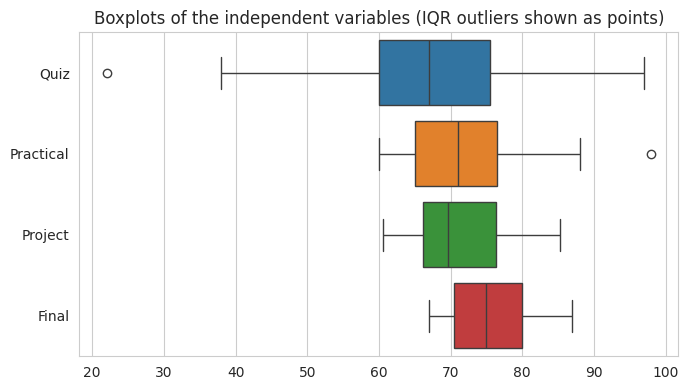

In [9]:
# Values outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR] are outliers for each independent variable.
outlier_frames = []
for col in MARK_COLS:
    q1, q3 = reg_df[col].quantile(0.25), reg_df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = reg_df[(reg_df[col] < low) | (reg_df[col] > high)]
    print(f"{col:10s} Q1={q1:6.2f} Q3={q3:6.2f} IQR={iqr:6.2f} bounds=[{low:6.2f}, {high:6.2f}] outliers={len(out)}")
    outlier_frames.append(out)

all_outliers = pd.concat(outlier_frames).drop_duplicates()        # combine + remove duplicates
print("\nOutlier records detected:\n", all_outliers.round(2).to_string(index=False))
reg_clean = reg_df.drop(index=all_outliers.index)                  # remove outlier rows
print(f"\nOutlier rows removed: {len(all_outliers)} | Records remaining: {len(reg_clean)}")

# Boxplots of the independent variables
plt.figure(figsize=(7, 4))
sns.boxplot(data=reg_df[MARK_COLS], orient="h")
plt.title("Boxplots of the independent variables (IQR outliers shown as points)")
plt.tight_layout(); plt.show()

In [10]:
X_reg = reg_clean[MARK_COLS]
y_reg = reg_clean["Total"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE)
print("Regression train:", Xr_train.shape, "| test:", Xr_test.shape)

Regression train: (16, 4) | test: (5, 4)


In [11]:
# Every model is a pipeline:  PolynomialFeatures -> StandardScaler -> estimator
# (degree = 1 means "no polynomial terms"). The alpha (and l1_ratio) of Ridge / Lasso / Elastic Net
# are chosen by 4-fold cross-validation on the TRAINING data only.
def make_pipe(estimator, degree=1):
    return Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", estimator),
    ])

alphas = np.logspace(-4, 1, 30)
reg_models = {
    "Multiple Linear Regression": make_pipe(LinearRegression(), 1),
    "Polynomial Regression (deg 2)": make_pipe(LinearRegression(), 2),
    "Ridge Regression": make_pipe(RidgeCV(alphas=alphas, cv=4), 1),
    "Lasso Regression": make_pipe(LassoCV(alphas=alphas, cv=4, max_iter=100000, random_state=RANDOM_STATE), 1),
    "Elastic Net Regression": make_pipe(
        ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9, 1.0], alphas=alphas, cv=4, max_iter=100000,
                     random_state=RANDOM_STATE), 1),
}
# Extra models beyond the lecture slides (for the additional-points note)
bonus_models = {
    "[Bonus] Polynomial Ridge (deg 2)": make_pipe(RidgeCV(alphas=np.logspace(-3, 3, 30), cv=4), 2),
    "[Bonus] Random Forest Regressor": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    "[Bonus] Gradient Boosting Regressor": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

In [12]:
def evaluate_reg(models):
    rows, preds = [], {}
    for name, mdl in models.items():
        mdl.fit(Xr_train, yr_train)
        p = mdl.predict(Xr_test)
        preds[name] = p
        rows.append({"Model": name,
                     "MSE": mean_squared_error(yr_test, p),
                     "RMSE": np.sqrt(mean_squared_error(yr_test, p)),
                     "R2 (test)": r2_score(yr_test, p),
                     "R2 (train)": r2_score(yr_train, mdl.predict(Xr_train))})
    return pd.DataFrame(rows), preds

reg_results, reg_preds = evaluate_reg(reg_models)
bonus_results, bonus_preds = evaluate_reg(bonus_models)

print("=== Required regression models ===")
print(reg_results.sort_values("R2 (test)", ascending=False).round(6).to_string(index=False))
print("\n=== Additional models (bonus) ===")
print(bonus_results.sort_values("R2 (test)", ascending=False).round(6).to_string(index=False))

rank_r2 = reg_results["R2 (test)"].round(6)
best_reg_name = reg_results.loc[rank_r2.idxmax(), "Model"]
best_reg = reg_models[best_reg_name]
print(f"\nBest-fit model (highest R-squared among the five required models): {best_reg_name}"
      f"  (R2 = {rank_r2.max():.6f})")

cmp = pd.DataFrame({"Excel_Row": reg_clean.loc[yr_test.index, "Excel_Row"].values,
                    "Observed": yr_test.values, "Predicted": reg_preds[best_reg_name]})
cmp["Error"] = cmp["Observed"] - cmp["Predicted"]
print("\nObserved vs predicted (test set):\n", cmp.round(4).to_string(index=False))

=== Required regression models ===
                        Model  MSE     RMSE  R2 (test)  R2 (train)
   Multiple Linear Regression  0.0 0.000000        1.0         1.0
Polynomial Regression (deg 2)  0.0 0.000000        1.0         1.0
             Ridge Regression  0.0 0.000032        1.0         1.0
             Lasso Regression  0.0 0.000227        1.0         1.0
       Elastic Net Regression  0.0 0.000227        1.0         1.0

=== Additional models (bonus) ===
                              Model      MSE     RMSE  R2 (test)  R2 (train)
   [Bonus] Polynomial Ridge (deg 2) 0.031436 0.177302   0.998781    0.999660
[Bonus] Gradient Boosting Regressor 2.214104 1.487986   0.914165    1.000000
    [Bonus] Random Forest Regressor 6.231826 2.496362   0.758409    0.967842

Best-fit model (highest R-squared among the five required models): Multiple Linear Regression  (R2 = 1.000000)

Observed vs predicted (test set):
  Excel_Row  Observed  Predicted  Error
         4     69.48      69.48  

Total = 0.0000 + 0.1000 * Quiz + 0.3000 * Practical + 0.3000 * Project + 0.3000 * Final

Intercept: 0.0
     Term  Coefficient
     Quiz          0.1
Practical          0.3
  Project          0.3
    Final          0.3

The model has recovered the weights of the assignment formula: Total = 0.1*Quiz + 0.3*Practical + 0.3*Project + 0.3*Final


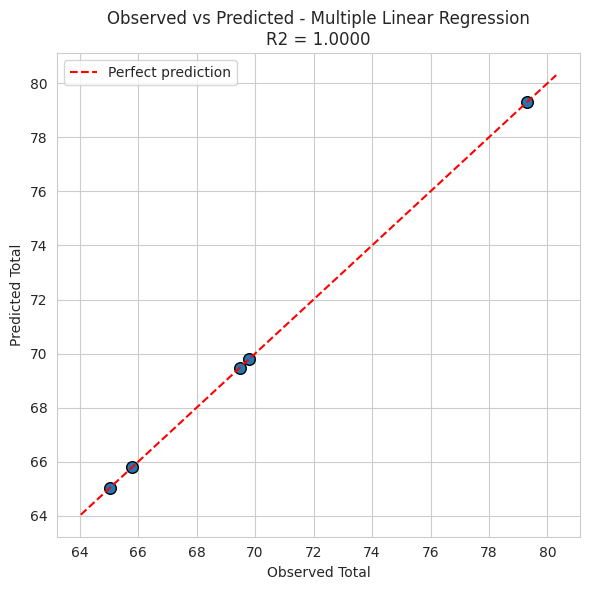

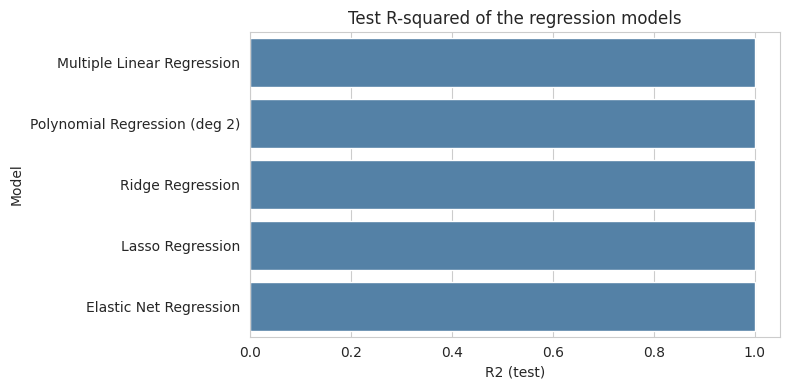

In [13]:
def original_scale_equation(pipe, feature_names):
    """Back-transform the coefficients of poly -> scaler -> linear model to original units."""
    poly, scaler, mdl = pipe.named_steps["poly"], pipe.named_steps["scaler"], pipe.named_steps["model"]
    names = poly.get_feature_names_out(feature_names)
    coef = mdl.coef_ / scaler.scale_
    intercept = mdl.intercept_ - np.sum(mdl.coef_ * scaler.mean_ / scaler.scale_)
    return names, coef, intercept

names, coefs, intercept = original_scale_equation(best_reg, MARK_COLS)
coefs = np.where(np.abs(coefs) < 1e-9, 0.0, coefs)             # remove floating-point dust
intercept = 0.0 if abs(intercept) < 1e-9 else intercept

def format_equation(decimals=4):
    terms = " ".join(f"{'+' if c >= 0 else '-'} {abs(c):.{decimals}f} * {n}" for n, c in zip(names, coefs) if c != 0)
    return f"Total = {intercept:.{decimals}f} {terms}"

print(format_equation(4))
print("\nIntercept:", round(intercept, 6))
print(pd.DataFrame({"Term": names, "Coefficient": coefs.round(6)}).to_string(index=False))
print("\nThe model has recovered the weights of the assignment formula: "
      "Total = 0.1*Quiz + 0.3*Practical + 0.3*Project + 0.3*Final")

# Plot observed vs predicted with the red perfect-prediction diagonal
plt.figure(figsize=(6, 6))
plt.scatter(yr_test, reg_preds[best_reg_name], s=70, edgecolor="k")
lims = [min(yr_test.min(), reg_preds[best_reg_name].min()) - 1, max(yr_test.max(), reg_preds[best_reg_name].max()) + 1]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Observed Total"); plt.ylabel("Predicted Total")
plt.title(f"Observed vs Predicted - {best_reg_name}\nR2 = {r2_score(yr_test, reg_preds[best_reg_name]):.4f}")
plt.legend(); plt.tight_layout(); plt.show()

# Bar chart of R2 for all required models
plt.figure(figsize=(8, 4))
sns.barplot(data=reg_results, y="Model", x="R2 (test)", color="steelblue")
plt.title("Test R-squared of the regression models"); plt.xlim(min(0, reg_results["R2 (test)"].min() - 0.05), 1.05)
plt.tight_layout(); plt.show()

In [15]:
five = reg_clean.sample(5, random_state=7).copy()

def predict_by_equation(row):
    total = intercept
    for n, c in zip(names, coefs):
        term = 1.0
        for part in n.split(" "):
            if "^" in part:
                base, power = part.split("^")
                term *= row[base] ** int(power)
            else:
                term *= row[part]
        total += c * term
    return total

five["Predicted (equation)"] = five.apply(predict_by_equation, axis=1)
five["Predicted (model check)"] = best_reg.predict(five[MARK_COLS])
five["Error (Obs - Pred)"] = five["Total"] - five["Predicted (equation)"]
five = five.rename(columns={"Total": "Observed Total"})
print("Equation used:")
print(format_equation(4), "\n")
print(five[["Excel_Row"] + MARK_COLS + ["Observed Total", "Predicted (equation)",
                                         "Predicted (model check)", "Error (Obs - Pred)"]].round(2).to_string(index=False))

first = five.iloc[0]
calc = " + ".join(f"{c:.1f}*{first[n]:.2f}" for n, c in zip(names, coefs) if c != 0)
print(f"\nWorked example (Excel row {int(first['Excel_Row'])}):  Total = {calc} = {first['Predicted (equation)']:.2f}")
print("Paper graph hint -> X axis (Observed): %d to %d | Y axis (Predicted): same range | draw the y = x line."
      % (np.floor(five["Observed Total"].min() / 5) * 5, np.ceil(five["Observed Total"].max() / 5) * 5))
five.to_csv("regression_5_random_records.csv", index=False)
print("Saved: regression_5_random_records.csv")

Equation used:
Total = 0.0000 + 0.1000 * Quiz + 0.3000 * Practical + 0.3000 * Project + 0.3000 * Final 

 Excel_Row  Quiz  Practical  Project  Final  Observed Total  Predicted (equation)  Predicted (model check)  Error (Obs - Pred)
         5  74.0      68.00     67.0     73           69.80                 69.80                    69.80                -0.0
        10  71.0      72.76     64.6     70           69.31                 69.31                    69.31                -0.0
         6  88.0      86.00     75.6     74           79.48                 79.48                    79.48                -0.0
        25  75.0      63.00     71.0     72           69.30                 69.30                    69.30                -0.0
        17  38.0      72.76     64.6     77           68.11                 68.11                    68.11                 0.0

Worked example (Excel row 5):  Total = 0.1*74.00 + 0.3*68.00 + 0.3*67.00 + 0.3*73.00 = 69.80
Paper graph hint -> X axis (Observed): 

# 3. CLASSIFICATION MODEL

In [16]:
CLASS_THRESHOLD = 75
df["Performance"] = np.where(df["Total"] >= CLASS_THRESHOLD, "High Performer", "Standard")
df["Performance_num"] = (df["Performance"] == "High Performer").astype(int)     # label encoding
print(f"Criterion: Total >= {CLASS_THRESHOLD} -> High Performer, otherwise Standard")
print(df["Performance"].value_counts())
print((df["Performance"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

X_cls = df[MARK_COLS]
y_cls = df["Performance_num"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cls, y_cls, test_size=0.20, random_state=RANDOM_STATE, stratify=y_cls)   # stratify keeps the class ratio
print("\nTrain:", Xc_train.shape, " Test:", Xc_test.shape)
print("High Performers in train: %d | in test: %d" % (yc_train.sum(), yc_test.sum()))

Criterion: Total >= 75 -> High Performer, otherwise Standard
Performance
Standard          15
High Performer     8
Name: count, dtype: int64
Performance
Standard          65.2 %
High Performer    34.8 %
Name: proportion, dtype: object

Train: (18, 4)  Test: (5, 4)
High Performers in train: 6 | in test: 2


=== Classification performance (positive class = High Performer) ===
Left block: 20 % test set | Right block (CV ...): repeated cross-validation on all records

                           Accuracy  Precision  Recall  F1-score  CV Accuracy  CV Precision  CV Recall   CV F1
Model                                                                                                         
Logistic Regression             1.0        1.0     1.0       1.0       1.0000        1.0000     1.0000  1.0000
K-Nearest Neighbors             1.0        1.0     1.0       1.0       0.9517        0.9083     1.0000  0.9450
Support Vector Machine          1.0        1.0     1.0       1.0       0.9642        0.9583     0.9625  0.9500
Decision Tree                   1.0        1.0     1.0       1.0       0.7983        0.7600     0.6625  0.6701
Random Forest                   1.0        1.0     1.0       1.0       0.8892        0.9292     0.7375  0.7992
[Bonus] Gradient Boosting       1.0        1.0     1.0       1

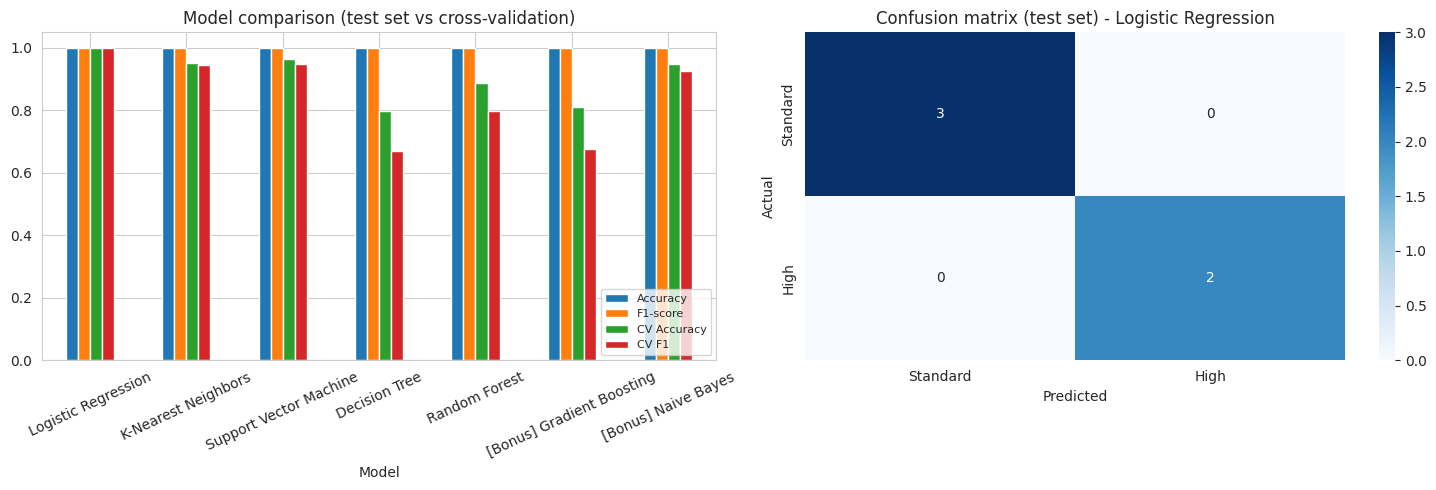


Feature importance / coefficients of the best model:
 Final        1.2098
Quiz         0.9150
Project      0.8570
Practical    0.7769
dtype: float64


In [17]:
cls_models = {
    "Logistic Regression": LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=3),
    "Support Vector Machine": SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=4, class_weight="balanced",
                                            random_state=RANDOM_STATE),
    # Beyond the lecture slides (additional points)
    "[Bonus] Gradient Boosting": GradientBoostingClassifier(n_estimators=100, max_depth=2, random_state=RANDOM_STATE),
    "[Bonus] Naive Bayes": GaussianNB(),
}

cv = RepeatedStratifiedKFold(n_splits=4, n_repeats=10, random_state=RANDOM_STATE)
fitted, rows = {}, []
for name, est in cls_models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", est)])
    pipe.fit(Xc_train, yc_train)
    pred = pipe.predict(Xc_test)
    cvres = cross_validate(pipe, X_cls, y_cls, cv=cv, scoring=["accuracy", "precision", "recall", "f1"])
    fitted[name] = pipe
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(yc_test, pred),
                 "Precision": precision_score(yc_test, pred, zero_division=0),
                 "Recall": recall_score(yc_test, pred, zero_division=0),
                 "F1-score": f1_score(yc_test, pred, zero_division=0),
                 "CV Accuracy": cvres["test_accuracy"].mean(),
                 "CV Precision": cvres["test_precision"].mean(),
                 "CV Recall": cvres["test_recall"].mean(),
                 "CV F1": cvres["test_f1"].mean()})

cls_results = pd.DataFrame(rows).set_index("Model")
print("=== Classification performance (positive class = High Performer) ===")
print("Left block: 20 % test set | Right block (CV ...): repeated cross-validation on all records\n")
print(cls_results.round(4).to_string())

# Best-fit classifier among the five required models: highest cross-validated F1 (the test set of
# ~5 records is too small to separate the models); ties are broken by the test-set F1.
required = [m for m in cls_results.index if not m.startswith("[Bonus]")]
ranked = cls_results.loc[required].sort_values(["CV F1", "F1-score"], ascending=False)
best_cls_name = ranked.index[0]
best_cls = fitted[best_cls_name]
print(f"\nBest-fit classifier (highest CV F1, ties -> test F1): {best_cls_name}")
print(f"Best overall including bonus models                : {cls_results['CV F1'].idxmax()}")

best_pred = best_cls.predict(Xc_test)
labels = ["Standard", "High Performer"]
print(f"\nClassification report on the test set - {best_cls_name}")
print(classification_report(yc_test, best_pred, labels=[0, 1], target_names=labels, digits=4, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
cls_results[["Accuracy", "F1-score", "CV Accuracy", "CV F1"]].plot(kind="bar", ax=ax[0], rot=25)
ax[0].set_title("Model comparison (test set vs cross-validation)"); ax[0].set_ylim(0, 1.05)
ax[0].legend(loc="lower right", fontsize=8)
sns.heatmap(confusion_matrix(yc_test, best_pred, labels=[0, 1]), annot=True, fmt="d", cmap="Blues", ax=ax[1],
            xticklabels=["Standard", "High"], yticklabels=["Standard", "High"])
ax[1].set_title(f"Confusion matrix (test set) - {best_cls_name}")
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Actual")
plt.tight_layout(); plt.show()

# Which marks matter most for the best model (if it exposes importances / coefficients)
final_est = best_cls.named_steps["model"]
if hasattr(final_est, "feature_importances_"):
    imp = pd.Series(final_est.feature_importances_, index=MARK_COLS).sort_values(ascending=False)
elif hasattr(final_est, "coef_"):
    imp = pd.Series(final_est.coef_[0], index=MARK_COLS).sort_values(key=abs, ascending=False)
else:
    imp = None
if imp is not None:
    print("\nFeature importance / coefficients of the best model:\n", imp.round(4))

In [18]:
label_map = {0: "Standard", 1: "High Performer"}
all_pred = best_cls.predict(X_cls)
summary = pd.DataFrame({
    "Actual - test set": pd.Series(yc_test).map(label_map).value_counts(),
    "Predicted - test set": pd.Series(best_pred).map(label_map).value_counts(),
    "Actual - all students": y_cls.map(label_map).value_counts(),
    "Predicted - all students": pd.Series(all_pred).map(label_map).value_counts(),
}).reindex(["Standard", "High Performer"]).fillna(0).astype(int)
print(f"Number of elements in each category using the best-fit classifier ({best_cls_name}):")
print(summary.to_string())
print("(The 'all students' prediction includes the records the model was trained on.)")

Number of elements in each category using the best-fit classifier (Logistic Regression):
                Actual - test set  Predicted - test set  Actual - all students  Predicted - all students
Standard                        3                     3                     15                        15
High Performer                  2                     2                      8                         8
(The 'all students' prediction includes the records the model was trained on.)


# 4. CLUSTER ANALYSIS

 k  Inertia (WCSS)  Silhouette  Davies-Bouldin  Smallest cluster
 2         55.1386      0.3346          1.1112                 8
 3         42.6546      0.2848          1.1243                 5
 4         33.4927      0.2893          1.1015                 4
 5         25.5854      0.3407          0.8984                 2
 6         18.2277      0.3628          0.7452                 1
 7         14.8392      0.3432          0.7569                 1


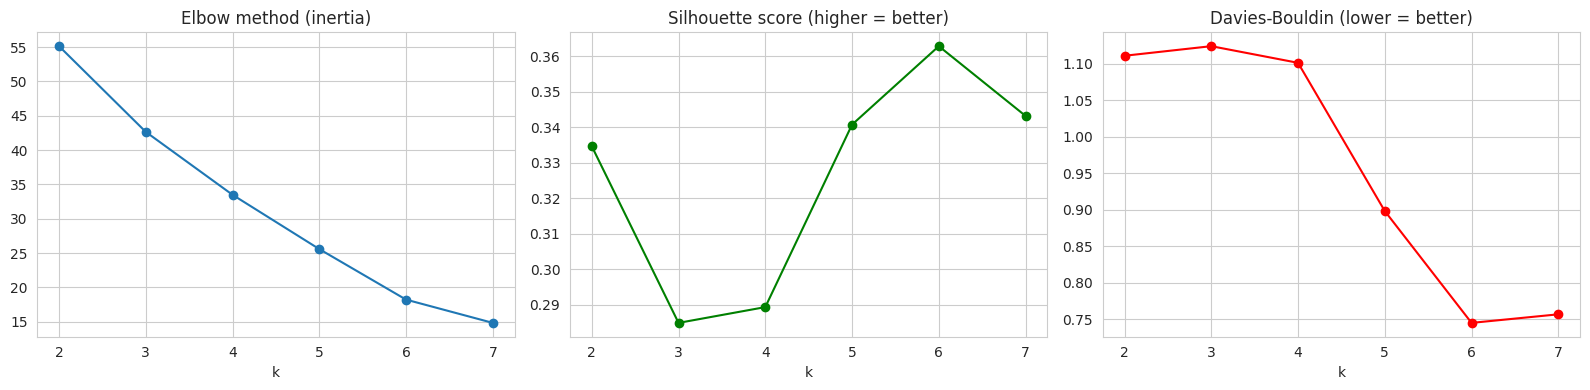


Optimal number of clusters: k = 4


In [19]:
CLUSTER_FEATURES = MARK_COLS
cl_scaler = StandardScaler()
Xc_scaled = cl_scaler.fit_transform(df[CLUSTER_FEATURES])

# Determine the optimal number of clusters: elbow (inertia) + silhouette + Davies-Bouldin
k_range = range(2, 8)
inertia, sil, dbi, smallest = [], [], [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit(Xc_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xc_scaled, km.labels_))
    dbi.append(davies_bouldin_score(Xc_scaled, km.labels_))
    smallest.append(int(np.bincount(km.labels_).min()))
k_table = pd.DataFrame({"k": list(k_range), "Inertia (WCSS)": inertia, "Silhouette": sil,
                        "Davies-Bouldin": dbi, "Smallest cluster": smallest})
print(k_table.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(k_range, inertia, "o-"); ax[0].set_title("Elbow method (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(k_range, sil, "o-", color="green"); ax[1].set_title("Silhouette score (higher = better)"); ax[1].set_xlabel("k")
ax[2].plot(k_range, dbi, "o-", color="red"); ax[2].set_title("Davies-Bouldin (lower = better)"); ax[2].set_xlabel("k")
plt.tight_layout(); plt.show()

K_OVERRIDE = None
candidates = k_table[(k_table["k"] >= 3) & (k_table["Smallest cluster"] >= 3)]
best_k = K_OVERRIDE or int(candidates.loc[candidates["Silhouette"].idxmax(), "k"])
print(f"\nOptimal number of clusters: k = {best_k}")

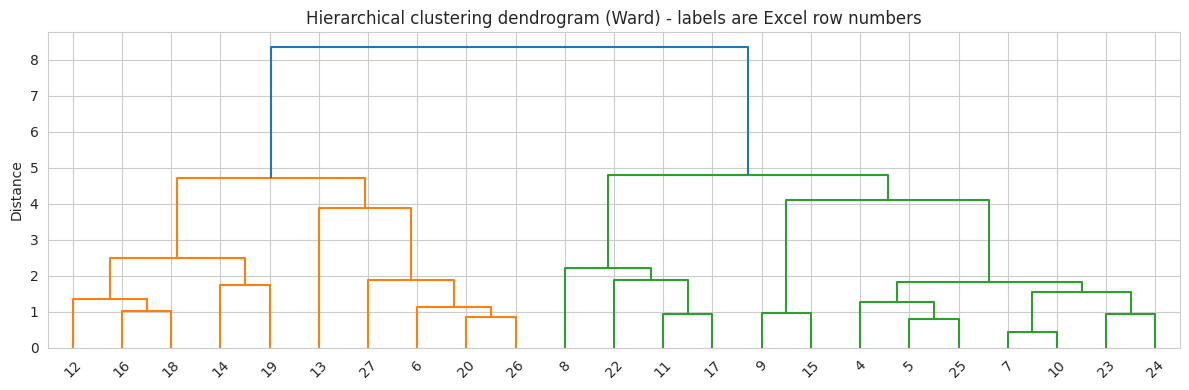

Hierarchical vs K-Means agreement (Adjusted Rand Index): 0.782
Silhouette  K-Means: 0.2893 | Hierarchical: 0.2887


In [20]:
kmeans = KMeans(n_clusters=best_k, n_init=50, random_state=RANDOM_STATE).fit(Xc_scaled)
df["Cluster"] = kmeans.labels_

# Hierarchical (Ward) clustering - the dendrogram uses all 23 students (labels = Excel row numbers)
Z = linkage(Xc_scaled, method="ward")
plt.figure(figsize=(12, 4))
dendrogram(Z, labels=df["Excel_Row"].astype(str).values)
plt.title("Hierarchical clustering dendrogram (Ward) - labels are Excel row numbers")
plt.ylabel("Distance"); plt.tight_layout(); plt.show()

hier = AgglomerativeClustering(n_clusters=best_k, linkage="ward").fit(Xc_scaled)
print("Hierarchical vs K-Means agreement (Adjusted Rand Index): %.3f" % adjusted_rand_score(kmeans.labels_, hier.labels_))
print("Silhouette  K-Means: %.4f | Hierarchical: %.4f"
      % (silhouette_score(Xc_scaled, kmeans.labels_), silhouette_score(Xc_scaled, hier.labels_)))

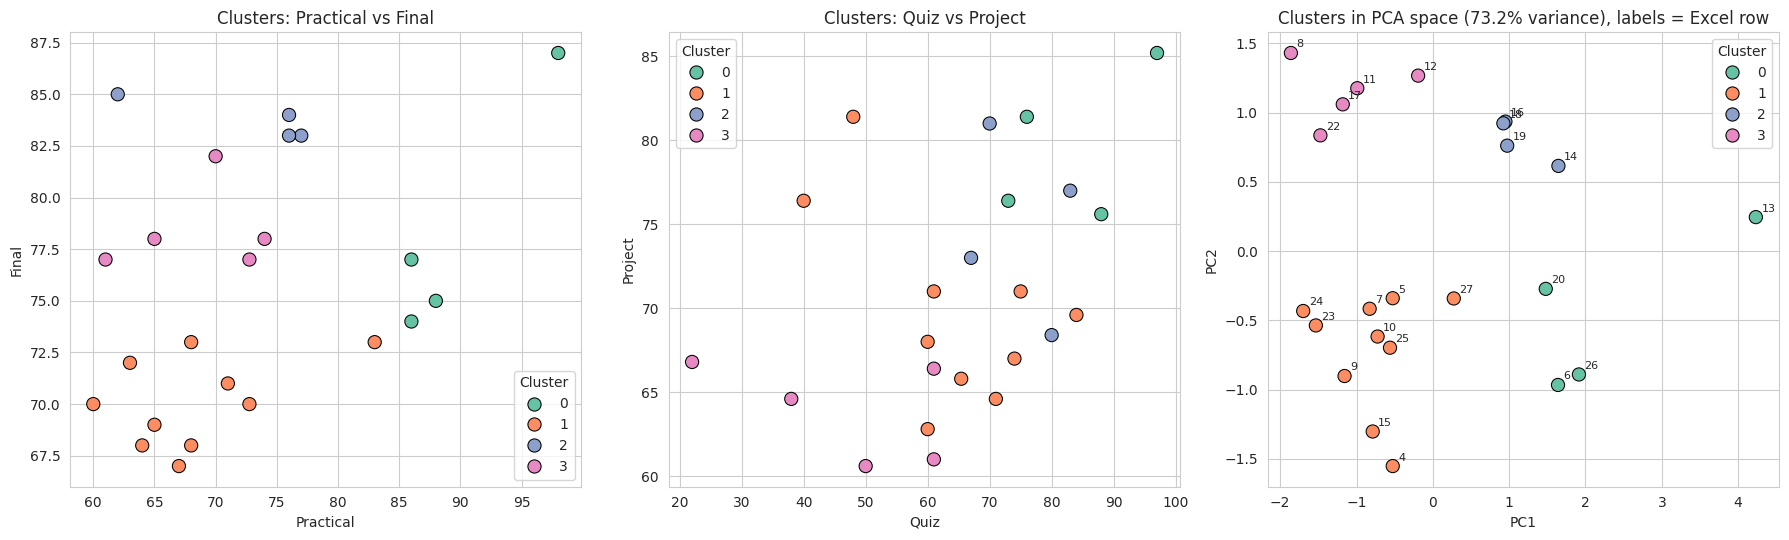

In [21]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(Xc_scaled)
pal = sns.color_palette("Set2", best_k)
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
sns.scatterplot(x=df["Practical"], y=df["Final"], hue=df["Cluster"], palette=pal, s=90, edgecolor="k", ax=ax[0])
ax[0].set_title("Clusters: Practical vs Final")
sns.scatterplot(x=df["Quiz"], y=df["Project"], hue=df["Cluster"], palette=pal, s=90, edgecolor="k", ax=ax[1])
ax[1].set_title("Clusters: Quiz vs Project")
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df["Cluster"], palette=pal, s=90, edgecolor="k", ax=ax[2])
for i, r in df["Excel_Row"].items():
    ax[2].annotate(str(r), (pcs[i, 0], pcs[i, 1]), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax[2].set_title(f"Clusters in PCA space ({pca.explained_variance_ratio_.sum() * 100:.1f}% variance), labels = Excel row")
ax[2].set_xlabel("PC1"); ax[2].set_ylabel("PC2")
plt.tight_layout(); plt.show()

In [22]:
profile = df.groupby("Cluster").agg(
    Students=("Total", "size"),
    Avg_Quiz=("Quiz", "mean"), Avg_Practical=("Practical", "mean"),
    Avg_Project=("Project", "mean"), Avg_Final=("Final", "mean"),
    Avg_Total=("Total", "mean"),
    Pct_High_Performers=("Performance_num", "mean"),
)
profile["Pct_High_Performers"] *= 100
profile["Divisions"] = df.groupby("Cluster")["Division"].apply(
    lambda s: ", ".join(f"{d}({n})" for d, n in s.value_counts().items()))
print(f"Overall average Total: {df['Total'].mean():.2f}\n")
print(profile.round(2).T.to_string())

Overall average Total: 72.40

Cluster                                           0                                       1                               2                               3
Students                                          4                                      10                               4                               5
Avg_Quiz                                       83.5                                   63.84                            75.0                            46.4
Avg_Practical                                  89.5                                   68.18                           72.75                           68.55
Avg_Project                                   79.65                                   69.76                           74.85                           63.88
Avg_Final                                     78.25                                    70.1                           83.75                            78.4
Avg_Total                         

In [25]:
overall_mean, overall_std = df[MARK_COLS].mean(), df[MARK_COLS].std()
order = profile["Avg_Total"].sort_values(ascending=False).index.tolist()

support_action = {
    "Quiz": "short weekly quizzes with quick feedback and revision sessions",
    "Practical": "extra supervised lab hours and guided practice tasks",
    "Project": "project milestones with regular supervisor check-ins and clear rubrics",
    "Final": "exam-technique workshops and past-paper practice",
}
role_action = {"Quiz": "quizzes", "Practical": "practical work", "Project": "projects", "Final": "final exams"}

for cid in order:
    r = profile.loc[cid]
    z = ((r[["Avg_Quiz", "Avg_Practical", "Avg_Project", "Avg_Final"]].values - overall_mean.values) / overall_std.values)
    z = pd.Series(z, index=MARK_COLS)
    weakest, strongest = z.idxmin(), z.idxmax()

    if cid == order[0]:
        label = "High Achievers"
        actions = ["Offer enrichment: advanced projects, competitions or honours tracks.",
                   f"Use them as peer tutors/mentors - they are especially strong in {role_action[strongest]}.",
                   "Recognise achievement (dean's list, certificates) to keep motivation high."]
    elif r["Avg_Total"] >= CLASS_THRESHOLD:
        label = "Strong Performers"
        actions = [f"Keep momentum with stretch tasks that build on their strength in {role_action[strongest]}.",
                   f"Small push where they are relatively weakest, {role_action[weakest]}: {support_action[weakest]}.",
                   "Invite them to study groups so they can move up to the High Achievers level."]
    elif cid == order[-1]:
        label = "Needs Support (at risk)"
        actions = ["Early-warning follow-up: meet the students individually and agree a recovery plan.",
                   f"Provide targeted help in {role_action[weakest]}: {support_action[weakest]}.",
                   "Assign a peer mentor from the High Achievers cluster and track progress every 2-3 weeks."]
    else:
        label = "Mid-Level Performers"
        actions = [f"Focus on their weakest area, {role_action[weakest]}: {support_action[weakest]}.",
                   f"Build on their relatively strongest area, {role_action[strongest]}, with stretch tasks.",
                   "Encourage regular revision groups to move them up to the next level."]

    print(f"\nCLUSTER {cid} - {label}  ({int(r['Students'])} students)")
    print(f"  Avg Quiz {r['Avg_Quiz']:.1f} | Practical {r['Avg_Practical']:.1f} | Project {r['Avg_Project']:.1f} | "
          f"Final {r['Avg_Final']:.1f} | Total {r['Avg_Total']:.1f} | High performers {r['Pct_High_Performers']:.0f}%")
    print(f"  Divisions: {r['Divisions']}")
    print(f"  Compared with the class average -> strongest: {strongest} ({z[strongest]:+.2f} sd), weakest: {weakest} ({z[weakest]:+.2f} sd)")
    print("  Strategy:")
    for a in actions:
        print("   -", a)


CLUSTER 0 - High Achievers  (4 students)
  Avg Quiz 83.5 | Practical 89.5 | Project 79.7 | Final 78.2 | Total 82.6 | High performers 100%
  Divisions: ENG(1), APP(1), BUS(1), CIS(1)
  Compared with the class average -> strongest: Practical (+1.69 sd), weakest: Final (+0.42 sd)
  Strategy:
   - Offer enrichment: advanced projects, competitions or honours tracks.
   - Use them as peer tutors/mentors - they are especially strong in practical work.
   - Recognise achievement (dean's list, certificates) to keep motivation high.

CLUSTER 2 - Strong Performers  (4 students)
  Avg Quiz 75.0 | Practical 72.8 | Project 74.8 | Final 83.8 | Total 76.9 | High performers 100%
  Divisions: EDU(1), ENG(1), BUS(1), APP(1)
  Compared with the class average -> strongest: Final (+1.33 sd), weakest: Practical (-0.00 sd)
  Strategy:
   - Keep momentum with stretch tasks that build on their strength in final exams.
   - Small push where they are relatively weakest, practical work: extra supervised lab hours